Original setting (maxRoomSize=4)
Overall map dimensions: 25 x 25
Configured maxRoomSize: 4
Actual room dimensions exposed by this MiniGrid version: [(np.int64(4), np.int64(4)), (np.int64(4), np.int64(4))]

Enlarged-room setting (maxRoomSize=10)
Overall map dimensions: 25 x 25
Configured maxRoomSize: 10
Actual room dimensions exposed by this MiniGrid version: [(np.int64(8), np.int64(7)), (np.int64(7), np.int64(4))]

Saved comparison image to: grid_size_comparison.png


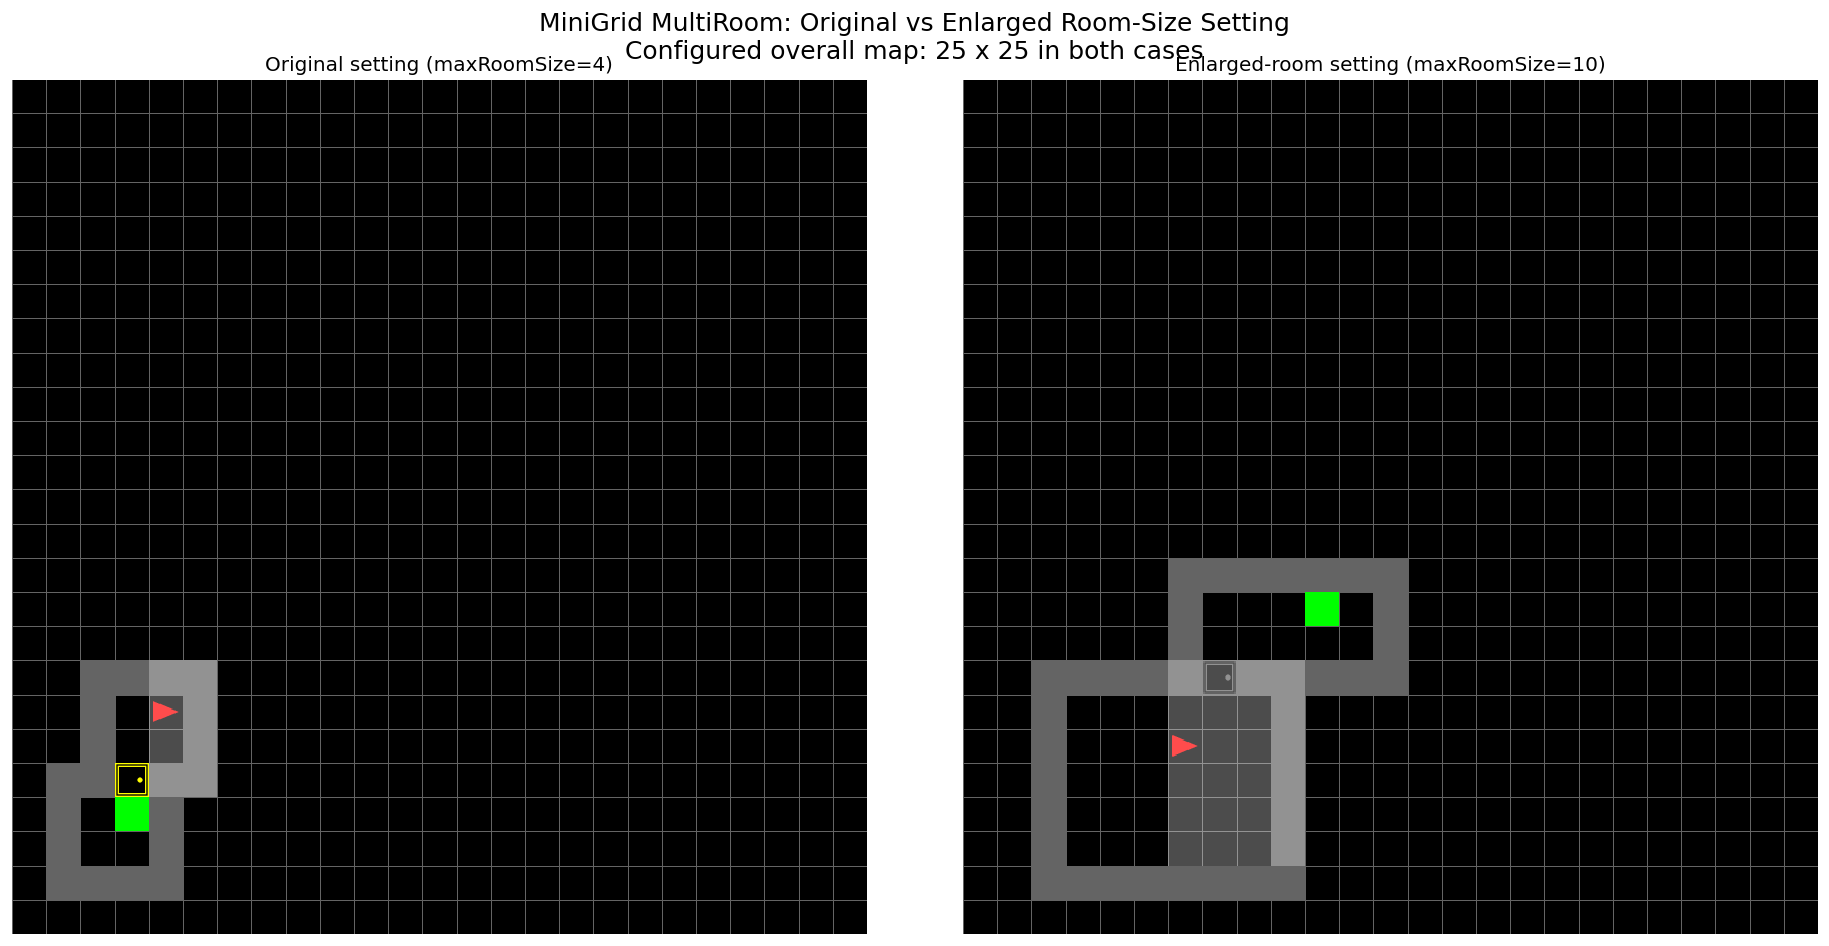

In [1]:
"""
MiniGrid MultiRoom room-size and grid-size comparison.
Compares maxRoomSize=4 with maxRoomSize=10 while keeping the configured
overall map dimensions at 25 x 25. Display size does not change the environment.
"""
import gymnasium as gym
import minigrid
import matplotlib.pyplot as plt

ENV_ID = "MiniGrid-MultiRoom-N2-S4-v0"
MAP_WIDTH, MAP_HEIGHT = 25, 25
SEED = 42
CONFIGS = [
    ("Original setting (maxRoomSize=4)", 4),
    ("Enlarged-room setting (maxRoomSize=10)", 10),
]

def main():
    fig, axes = plt.subplots(1, 2, figsize=(16, 8), dpi=120)
    for ax, (label, room_size) in zip(axes, CONFIGS):
        env = gym.make(
            ENV_ID,
            maxRoomSize=room_size,
            width=MAP_WIDTH,
            height=MAP_HEIGHT,
            render_mode="rgb_array",
        )
        try:
            env.reset(seed=SEED)
            image = env.unwrapped.get_frame()
            ax.imshow(image, interpolation="nearest")
            ax.set_title(label, fontsize=12)
            ax.axis("off")

            rooms = getattr(env.unwrapped, "rooms", [])
            dimensions = [getattr(room, "size", None) for room in rooms]
            print(label)
            print(f"Overall map dimensions: {env.unwrapped.width} x {env.unwrapped.height}")
            print(f"Configured maxRoomSize: {env.unwrapped.maxRoomSize}")
            print(f"Actual room dimensions exposed by this MiniGrid version: {dimensions}")
            print()
        finally:
            env.close()

    fig.suptitle(
        "MiniGrid MultiRoom: Original vs Enlarged Room-Size Setting\n"
        "Configured overall map: 25 x 25 in both cases",
        fontsize=15,
    )
    fig.tight_layout()
    output_path = "grid_size_comparison.png"
    fig.savefig(output_path, bbox_inches="tight")
    print(f"Saved comparison image to: {output_path}")
    plt.show()

if __name__ == "__main__":
    main()
